# 04 · Battery and electric vehicle together

Both flexible assets in the same house. The interesting question is whether the two interact: the battery could
discharge into the car, the car could take the surplus the battery cannot hold, and both compete for the contracted
power at night.

The reference for the saving is the house with the battery left alone (self-consumption) and the car charging on
arrival, i.e. what the equipment does without an optimizer. As in notebook 02, the energy left in the battery at
the end of the horizon is valued, so the two plans are compared on the same footing.

In [1]:
import sys
from pathlib import Path

# make the package importable without installing it (the notebooks live one level below the repo root)
src = Path().resolve().parent / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

import pandas as pd
pd.set_option("display.precision", 3)

In [2]:
from fennec import HuaweiLuna2000Controller, Load, SmartHome
from fennec.examples import (
    battery_and_vehicle, default_horizon, porto_battery, porto_grid, porto_load, porto_pv, porto_vehicle,
)
from fennec.utils import compare, energy_balance, plot_comparison, plot_dispatch

horizon = default_horizon()
grid, pv, house, car = porto_grid(), porto_pv(horizon), porto_load(horizon), porto_vehicle(horizon)
available = [horizon.energy(grid.contracted_power_kw) + p - l for p, l in zip(pv.energy, house.energy)]
alone = SmartHome(
    horizon,
    grid,
    [
        pv,
        house,
        porto_battery(horizon, HuaweiLuna2000Controller(mode="self_consumption")),
        Load("car_on_arrival", energy=car.charge_on_arrival(horizon, max_energy=available)),
    ],
)

results = {
    "no optimizer": alone.solve(time_limit=120),
    "optimized": battery_and_vehicle(horizon).solve(time_limit=120),
}
compare(results, reference="no optimizer")

,status,bill,stored_value,objective,import_kwh,export_kwh,solve_s,final_soc,commands,saving,saving_pct
no optimizer,optimal,12.382,-0.029,12.412,94.94,2.66,0.09,47.3,0,0.000,0.0
optimized,optimal,9.464,-0.029,9.526,79.75,2.66,14.39,47.3,6,2.885,23.2


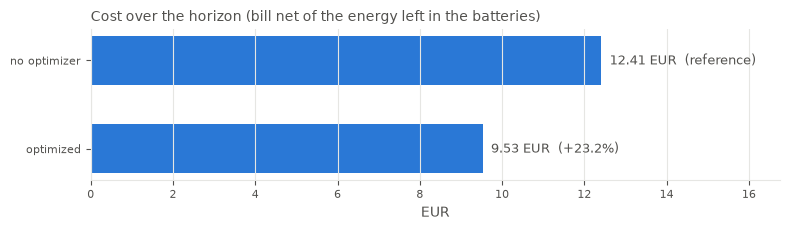

In [3]:
plot_comparison(results, reference="no optimizer");

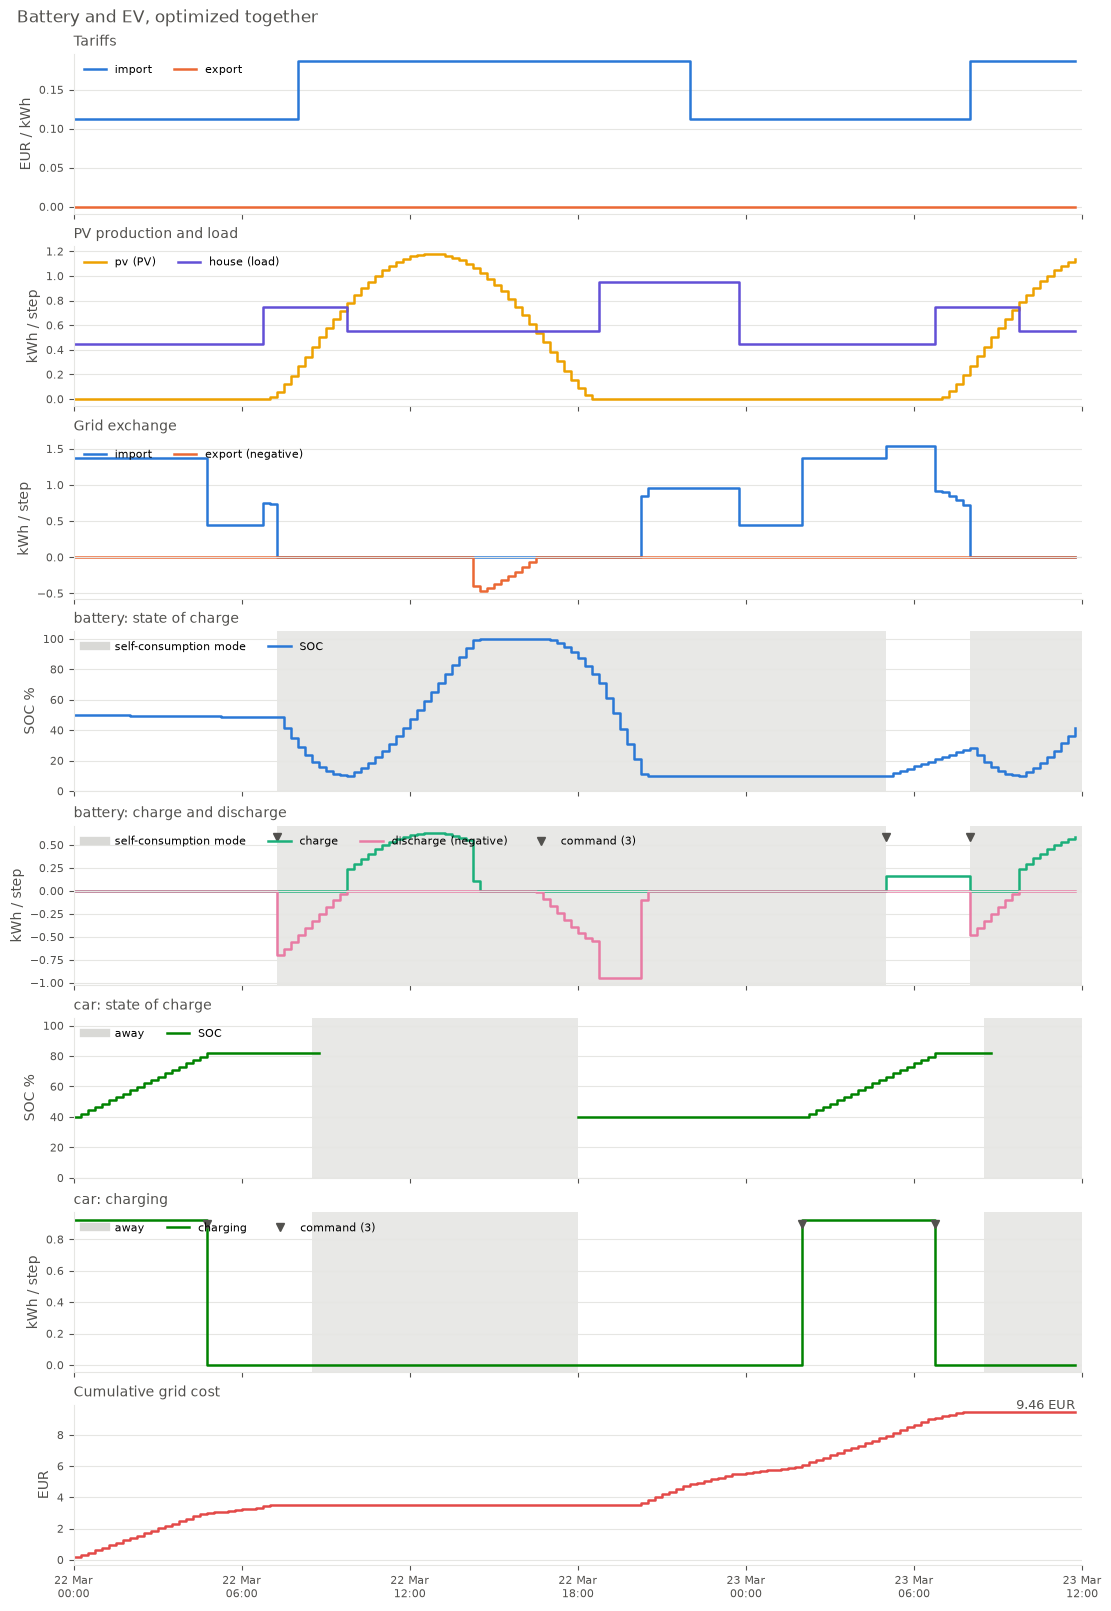

In [4]:
plot_dispatch(results["optimized"], title="Battery and EV, optimized together");

In [5]:
energy_balance(results["optimized"])

,kind,to_house_kwh,from_house_kwh,cost
asset,,,,
grid,grid,79.748,2.664,9.464
pv,pv,45.800,0.000,0.000
house,load,0.000,86.500,0.000
battery,battery,14.105,15.340,0.030
car,ev,0.000,35.150,0.003


## Where to go from here

* Add a new device: subclass `fennec.assets.Asset`, expose `energy_from`, `energy_to` and `cost` per step
  (a heat pump or a water heater needs a thermal state the same way a battery needs a SOC).
* Add a new battery brand: subclass `fennec.controllers.BatteryController` and write that inverter's modes and
  commands on top of the shared battery physics.
* Run the same scenario from JSON with `python -m fennec scenario.json` (see `fennec.scenario`).